# m13 - GAEZ at ~9 km vs 1 km: What the Finer Target Changes

**Background.** The modeling notebooks m01-m12 learn GAEZ v5 at 30 arc-seconds (~1 km), which
`scripts/preprocessing/12_gaez_v5_1km.ipynb` adds to the warehouse as `gaez1k_index_<crop>`. The first round of
experiments used the 5 arc-minute product (~9 km): only 164 GAEZ pixels cover Banten, so every 1 km cell inside one pixel
carried the same target. This notebook compares the two targets directly.

**Questions.**
1. How much local detail does the 1 km product add?
2. Do the same models learn both targets equally well, and does random K-fold overstate them equally?
3. Models trained on the ~9 km target predict from 1 km drivers, so their predictions vary inside a GAEZ pixel. Does that
   sub-pixel detail match the real 1 km GAEZ? (In the first round m08 and m10 could only check it against GCS 2024, a
   different model.)

**Setup.** Cells with a 1 km value for all ten crops (GAEZ leaves no value where it marks no cropland or water). Same 14
drivers, models and CV schemes as m01, one repeat, identical folds for both targets. Workers capped at `E.N_JOBS`; the whole
notebook takes 1-2 minutes.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.ndimage import gaussian_filter
from sklearn.metrics import r2_score

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table(complete=False)   # the whole grid: the smoothing below needs every cell
K1 = {c: E.target_col(c, "1km") for c in E.CROPS}   # GAEZ v5 at 30 arc-sec, the target of m01-m12
K9 = {c: E.target_col(c, "9km") for c in E.CROPS}   # GAEZ v5 at 5 arc-min, the target of the first round


def smoothed(col, sigma=3.0):
    """Gaussian blur (sigma in 1 km cells) over the valid cells of the grid, like the dashboard's display aid."""
    r, c = df["row"].to_numpy(), df["col"].to_numpy()
    v = df[col].to_numpy(float)
    ok = ~np.isnan(v)
    grid, w = np.zeros((r.max() + 1, c.max() + 1)), np.zeros((r.max() + 1, c.max() + 1))
    grid[r[ok], c[ok]], w[r[ok], c[ok]] = v[ok], 1.0
    num, den = gaussian_filter(grid, sigma, mode="constant"), gaussian_filter(w, sigma, mode="constant")
    return np.where(den > 1e-6, num / np.maximum(den, 1e-6), np.nan)[r, c]


df = pd.concat([df, pd.DataFrame({f"smooth9__{c}": smoothed(K9[c]) for c in E.CROPS}, index=df.index)], axis=1)
full = df[list(K1.values())].notna().all(axis=1)
d = df[full].reset_index(drop=True)
print(f"{len(df)} cells; {len(d)} have a 1 km GAEZ value for all ten crops and are used here "
      f"({int((~full).sum())} left out: no cropland or water for at least one crop); {d['pix'].nunique()} GAEZ pixels")

9333 cells; 9129 have a 1 km GAEZ value for all ten crops and are used here (204 left out: no cropland or water for at least one crop); 163 GAEZ pixels


## 1. What the 1 km target adds

`within_pixel_share` is the share of a target's variance that lies inside the ~9 km GAEZ pixels, i.e. variation a model
of the ~9 km target is never scored on. For the ~9 km target it is only the few percent that come from cells straddling a
pixel edge.

In [3]:
rows = []
for c in E.CROPS:
    y1, y9 = d[K1[c]], d[K9[c]]
    rows.append({"crop": c, "spearman_9km_vs_1km": E.spearman(y9.to_numpy(), y1.to_numpy()),
                 "r2_9km_as_1km": r2_score(y1, y9),
                 "within_pixel_share_9km": (y9 - y9.groupby(d["pix"]).transform("mean")).var() / y9.var(),
                 "within_pixel_share_1km": (y1 - y1.groupby(d["pix"]).transform("mean")).var() / y1.var(),
                 "suitable_cells_9km": int((y9 >= E.NOT_RECOMMENDED_THRESHOLD).sum()),
                 "suitable_cells_1km": int((y1 >= E.NOT_RECOMMENDED_THRESHOLD).sum())})
resolution = pd.DataFrame(rows).set_index("crop")
E.save_table(resolution.round(4), "m13_resolution", index=True)
resolution.round(3)

,spearman_9km_vs_1km,r2_9km_as_1km,within_pixel_share_9km,within_pixel_share_1km,suitable_cells_9km,suitable_cells_1km
crop,,,,,,
rice,0.888,0.828,0.023,0.181,1993,2181
maize,0.887,0.817,0.028,0.200,0,8
cassava,0.882,0.791,0.025,0.222,3145,3060
soybean,0.867,0.783,0.029,0.234,87,256
oilpalm,0.875,0.769,0.028,0.248,3945,3938
rubber,0.817,0.696,0.032,0.317,0,0
sugarcane,0.894,0.816,0.028,0.203,662,1186
coffee,0.884,0.769,0.029,0.206,2648,3098
cacao,0.855,0.717,0.035,0.256,1289,2502


## 2. The same models on both targets

The m01 setting run on the same cells and the same folds for both targets, so the two halves of the leaderboard differ only
in the target. Four models (ridge, ExtraTrees, HistGB, XGBoost) x 10 crops x 2 targets x 3 schemes = 240 tasks.

In [4]:
MODELS = ["ridge", "et", "hgb", "xgb"]
SCHEMES = ["random", "block10", "pixel"]
targets = {f"{c}@{res}": d[cols[c]].to_numpy() for res, cols in (("1km", K1), ("9km", K9)) for c in E.CROPS}
cv, oof = E.run_grid(d, targets, MODELS, SCHEMES, n_repeats=1, keep_oof=True)
cv[["crop", "resolution"]] = cv["target"].str.split("@", expand=True)
E.save_table(cv, "m13_cv_raw")

240 tasks (4 models x 20 targets x 3 schemes x 1 repeats), 14 features


done in 74 s


WindowsPath('D:/Softwares/AnacondaProjects/GeoSuitability_AI_Analytics/scripts/modeling/results/m13_cv_raw.csv')

In [5]:
board = cv.groupby(["resolution", "model", "scheme"])["r2"].mean().unstack("scheme")[SCHEMES]
board["leakage_gap"] = board["random"] - board["pixel"]
board = board.reset_index().sort_values(["resolution", "pixel"], ascending=[False, False])
E.save_table(board.round(4), "m13_leaderboard")
board.round(3)

scheme,resolution,model,random,block10,pixel,leakage_gap
4,9km,et,0.968,0.874,0.831,0.137
5,9km,hgb,0.948,0.867,0.811,0.137
7,9km,xgb,0.940,0.862,0.811,0.129
6,9km,ridge,0.618,0.587,0.570,0.047
0,1km,et,0.915,0.811,0.819,0.096
1,1km,hgb,0.893,0.803,0.805,0.089
3,1km,xgb,0.885,0.802,0.805,0.081
2,1km,ridge,0.630,0.603,0.604,0.027


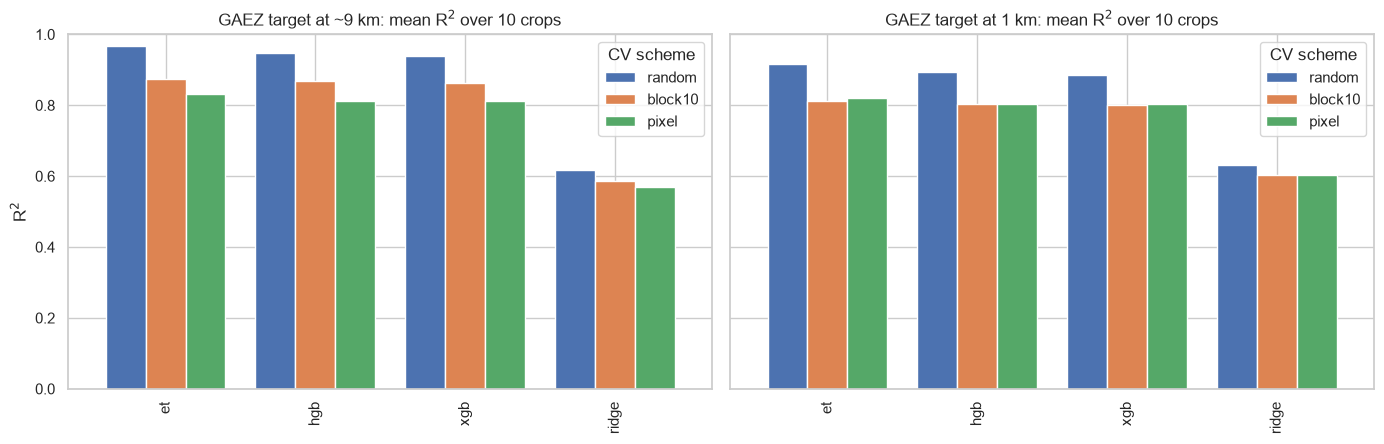

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, r in zip(axes, ["9km", "1km"]):
    b = board[board["resolution"] == r].set_index("model")[SCHEMES]
    b.plot.bar(ax=ax, width=0.8)
    ax.set(title=f"GAEZ target at {'~9 km' if r == '9km' else '1 km'}: mean R$^2$ over 10 crops", ylabel="R$^2$", xlabel="")
    ax.set_ylim(0, 1)
    ax.legend(title="CV scheme")
plt.tight_layout()
E.save_fig(fig, "m13_leaderboard")
plt.show()

In [7]:
per_crop = cv[cv["scheme"] == "pixel"].pivot_table(index="crop", columns=["model", "resolution"], values="r2")
per_crop.columns = [f"{m}@{r}" for m, r in per_crop.columns]
E.save_table(per_crop.reindex(E.CROPS).round(4), "m13_crop_r2_pixel", index=True)
per_crop.reindex(E.CROPS).round(3)

,et@1km,et@9km,hgb@1km,hgb@9km,ridge@1km,ridge@9km,xgb@1km,xgb@9km
crop,,,,,,,,
rice,0.849,0.865,0.835,0.839,0.645,0.630,0.835,0.849
maize,0.804,0.829,0.788,0.808,0.616,0.604,0.790,0.805
cassava,0.838,0.854,0.832,0.838,0.613,0.568,0.829,0.841
soybean,0.780,0.837,0.740,0.819,0.561,0.581,0.741,0.809
oilpalm,0.829,0.832,0.824,0.812,0.609,0.552,0.818,0.818
rubber,0.755,0.769,0.746,0.744,0.467,0.358,0.746,0.739
sugarcane,0.842,0.844,0.835,0.821,0.660,0.636,0.836,0.829
coffee,0.835,0.833,0.821,0.816,0.607,0.540,0.819,0.804
cacao,0.809,0.786,0.795,0.773,0.616,0.590,0.799,0.775


In [8]:
# Out-of-fold predictions of the models trained on the ~9 km target (pixel scheme), for the dashboard's error maps.
oof9 = d[["grid_id"]].copy()
for m in ["et", "hgb", "xgb"]:
    for c in E.CROPS:
        oof9[f"{m}__{c}"] = oof[(m, f"{c}@9km", "pixel", 0)]
print(E.save_oof(oof9, "m13_oof_9km_pixel"))

D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\experiments\m13_oof_9km_pixel.parquet


## 3. Was the sub-pixel detail of the ~9 km models real?

Candidate 1 km maps, each scored against the real 1 km GAEZ:

| candidate | what it is |
| --- | --- |
| `~9 km GAEZ as is` | the ~9 km value repeated over its pixel (no downscaling) |
| `~9 km GAEZ smoothed` | the ~9 km values blurred over ~3 km (the dashboard's display aid) |
| `ExtraTrees / HistGB / XGBoost, ~9 km target` | section 2: trained on the ~9 km target from 1 km drivers, whole pixels held out |
| `ExtraTrees, 1 km target` | section 2, whole pixels held out: what the drivers explain when the target has 1 km detail |

`within_pixel_rho` removes each pixel's mean from both maps and correlates what is left (Spearman): above 0 means the
candidate puts the 1 km detail in the right places.

In [9]:
def within_rho(pred, truth, pix):
    a = pred - pred.groupby(pix).transform("mean")
    b = truth - truth.groupby(pix).transform("mean")
    return E.spearman(a.to_numpy(), b.to_numpy())


def oof_of(model, crop, res):
    return pd.Series(oof[(model, f"{crop}@{res}", "pixel", 0)])


CANDIDATES = {"~9 km GAEZ as is": lambda c: d[K9[c]], "~9 km GAEZ smoothed": lambda c: d[f"smooth9__{c}"],
              "ExtraTrees, ~9 km target": lambda c: oof_of("et", c, "9km"), "HistGB, ~9 km target": lambda c: oof_of("hgb", c, "9km"),
              "XGBoost, ~9 km target": lambda c: oof_of("xgb", c, "9km"), "ExtraTrees, 1 km target": lambda c: oof_of("et", c, "1km")}
rows = []
for c in E.CROPS:
    truth = d[K1[c]]
    for name, get in CANDIDATES.items():
        pred = get(c)
        rows.append({"crop": c, "candidate": name, "r2_vs_1km": r2_score(truth, pred),
                     "spearman_vs_1km": E.spearman(pred.to_numpy(), truth.to_numpy()),
                     "within_pixel_rho": within_rho(pred, truth, d["pix"])})
down = pd.DataFrame(rows)
E.save_table(down.round(4), "m13_downscaling")
down.groupby("candidate", sort=False)[["r2_vs_1km", "spearman_vs_1km", "within_pixel_rho"]].mean().round(3)

,r2_vs_1km,spearman_vs_1km,within_pixel_rho
candidate,,,
~9 km GAEZ as is,0.784,0.876,0.279
~9 km GAEZ smoothed,0.771,0.871,0.412
"ExtraTrees, ~9 km target",0.724,0.847,0.476
"HistGB, ~9 km target",0.711,0.842,0.456
"XGBoost, ~9 km target",0.713,0.843,0.473
"ExtraTrees, 1 km target",0.819,0.901,0.707


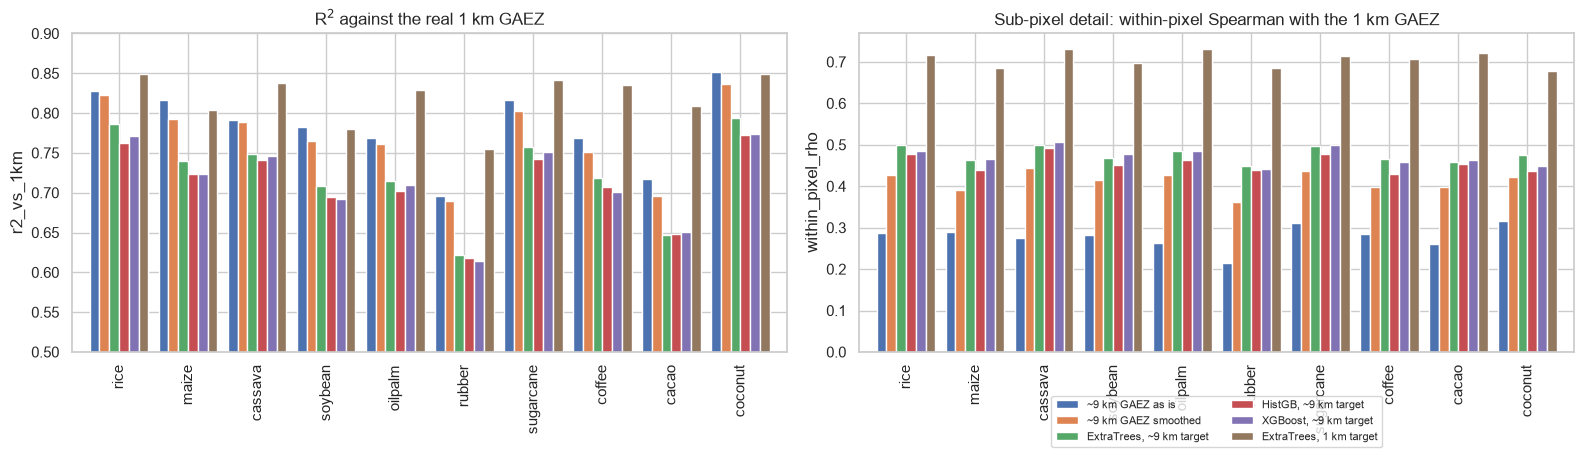

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, metric, title in [(axes[0], "r2_vs_1km", "R$^2$ against the real 1 km GAEZ"),
                          (axes[1], "within_pixel_rho", "Sub-pixel detail: within-pixel Spearman with the 1 km GAEZ")]:
    t = down.pivot(index="crop", columns="candidate", values=metric).reindex(index=E.CROPS, columns=list(CANDIDATES))
    t.plot.bar(ax=ax, width=0.85, legend=False)
    ax.set(title=title, xlabel="", ylabel=metric)
    ax.axhline(0, color="black", lw=0.8)
axes[0].set_ylim(0.5, 0.9)
axes[1].legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
E.save_fig(fig, "m13_downscaling")
plt.show()

## 4. Rice on the map

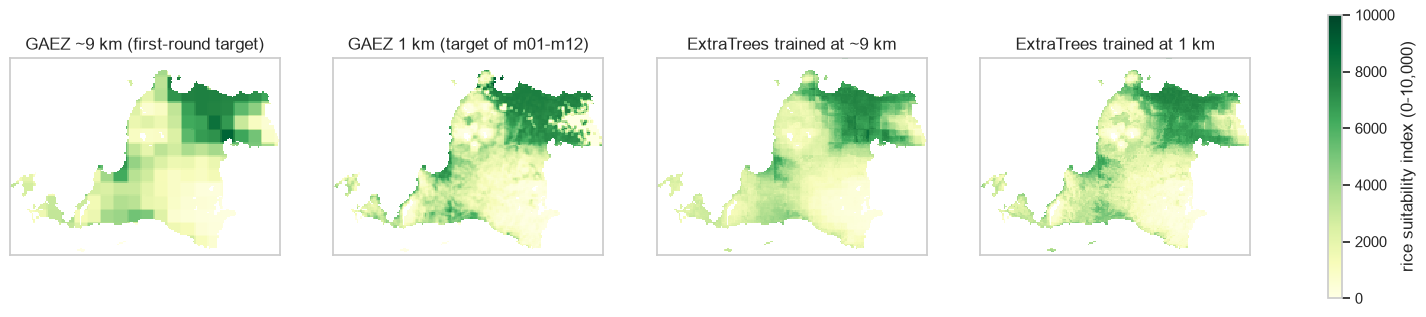

In [11]:
crop = "rice"
shape = (df["row"].max() + 1, df["col"].max() + 1)


def on_grid(values):
    z = np.full(shape, np.nan)
    z[d["row"].to_numpy(), d["col"].to_numpy()] = np.asarray(values, dtype=float)
    return z


panels = [(d[K9[crop]], "GAEZ ~9 km (first-round target)"), (d[K1[crop]], "GAEZ 1 km (target of m01-m12)"),
          (oof_of("et", crop, "9km"), "ExtraTrees trained at ~9 km"), (oof_of("et", crop, "1km"), "ExtraTrees trained at 1 km")]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (v, title) in zip(axes, panels):
    im = ax.imshow(on_grid(v), origin="lower", cmap="YlGn", vmin=0, vmax=10000, interpolation="nearest")
    ax.set(title=title)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="rice suitability index (0-10,000)")
E.save_fig(fig, "m13_maps_rice")
plt.show()

## Findings

* **The 1 km product carries real local detail.** It agrees with the ~9 km version on the broad pattern (Spearman
  0.82-0.91), but between a sixth and a third of its variance lies inside the ~9 km pixels, against 2-4 % for the
  ~9 km product. Some crops gain a lot of suitable land at 1 km: sugarcane 662 -> 1,186 cells with an index of 5,000
  or more, cacao 1,289 -> 2,502, soybean 87 -> 256.
* **The same models learn both targets about equally well** under pixel-grouped CV (ExtraTrees R² 0.82 at 1 km vs
  0.83 at ~9 km, ridge 0.60 vs 0.57), but random K-fold flattered the ~9 km models more (leakage gap 0.14 vs 0.10):
  there, neighbouring cells shared one target value. The ranking of the models does not change: ExtraTrees >
  HistGB ≈ XGBoost >> ridge.
* **The sub-pixel detail of the ~9 km models was partly real.** Within a pixel, models trained on the ~9 km target
  follow the 1 km GAEZ with a Spearman of about 0.47 (0.46-0.48 for the three tree models): better than blurring the
  ~9 km map (0.41), far from a model trained on the 1 km target (0.71). In the first round m08 found little agreement
  with GCS 2024 inside a pixel; against GAEZ's own 1 km product the downscaling does point the right way.
* **Over the whole map the published ~9 km value was the better stand-in for the 1 km index** (R² 0.78) than a
  surrogate that never saw the pixel (0.71-0.72). Now that the 1 km product is in the warehouse, the dashboard and
  m01-m12 use it directly.